# Multi-warehouse inventory: receding horizon control
Four-period horizon, ten implemented periods. No XR; inventory equality constraints. Demand and reference repeat the six-period workbook pattern through period 13. Delayed deliveries from implemented orders are carried into the next optimization. No terminal constraint or terminal cost beyond the original stage costs.

In [ ]:
%pip -q install pyscipopt openpyxl

In [ ]:
from google.colab import files
uploaded = files.upload()
filename = 'Multi-Warehouse-Inv-Con.xlsx'
assert filename in uploaded, 'Upload the original Excel workbook.'

Saving Multi-Warehouse-Inv-Con.xlsx to Multi-Warehouse-Inv-Con.xlsx


In [ ]:
import numpy as np
import pandas as pd
from openpyxl import load_workbook
from itertools import product
from pyscipopt import Model, quicksum

wb = load_workbook(filename, data_only=True)
T, W, S, I = range(6), range(3), range(3), range(3)
shapes = {'OC':(3,), **{k:(3,3) for k in ['UP','DR','SR','DC','SC','MS','HC','MW','prevI','IC']}, 'Iref':(6,3,3), 'DE':(6,3,3), 'WC':(3,3,3)}
P = {}
for name, shape in shapes.items():
    sheet, address = next(iter(wb.defined_names[name].destinations))
    values = [c.value for row in wb[sheet][address] for c in row]
    P[name] = np.array(values, dtype=float).reshape(shape)
    assert np.isfinite(P[name]).all(), name
    print(name, address, P[name].shape, '\n', P[name])
OC, UP, DR, SR, DC, SC, MS, HC, MW, prevI, IC, Iref, DE, WC = (P[k] for k in ['OC','UP','DR','SR','DC','SC','MS','HC','MW','prevI','IC','Iref','DE','WC'])
assert (OC > 0).all() and (IC >= 0).all()


OC $I$81:$K$81 (3,) 
 [40. 45. 20.]
UP $C$4:$E$6 (3, 3) 
 [[1. 1. 1.]
 [1. 2. 2.]
 [1. 1. 1.]]
DR $C$11:$E$13 (3, 3) 
 [[0.01 0.02 0.02]
 [0.02 0.05 0.05]
 [0.02 0.02 0.02]]
SR $C$19:$E$21 (3, 3) 
 [[0.01 0.02 0.02]
 [0.02 0.05 0.05]
 [0.02 0.02 0.02]]
DC $J$5:$L$7 (3, 3) 
 [[1.  2.  2. ]
 [1.  1.5 2.5]
 [1.5 1.5 2. ]]
SC $J$13:$L$15 (3, 3) 
 [[1.  2.  2. ]
 [1.5 2.5 2.5]
 [1.5 2.  2. ]]
MS $J$21:$L$23 (3, 3) 
 [[20. 30. 30.]
 [20. 35. 35.]
 [25. 20. 20.]]
HC $I$45:$K$47 (3, 3) 
 [[2. 3. 2.]
 [2. 3. 2.]
 [1. 1. 1.]]
MW $J$36:$L$38 (3, 3) 
 [[100. 100. 100.]
 [100. 100. 100.]
 [100. 100. 100.]]
prevI $U$27:$W$29 (3, 3) 
 [[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
IC $J$88:$L$90 (3, 3) 
 [[10. 10. 10.]
 [20. 10. 10.]
 [10. 10. 10.]]
Iref $C$28:$E$45 (6, 3, 3) 
 [[[50. 45. 40.]
  [35. 30. 25.]
  [20. 15. 10.]]

 [[50. 45. 40.]
  [35. 30. 25.]
  [20. 15. 10.]]

 [[50. 45. 40.]
  [35. 30. 25.]
  [20. 15. 10.]]

 [[50. 45. 40.]
  [35. 30. 25.]
  [20. 15. 10.]]

 [[50. 45. 40.]
  [35. 30. 25.]
  [2

In [ ]:
H, N = 4, 10
K = range(H)
# Forecast extension: replace these arrays with actual 13-period forecasts if available.
DE_full = DE[np.arange(N+H-1) % len(DE)].copy()
Iref_full = Iref[np.arange(N+H-1) % len(Iref)].copy()
COSTS = [1,2,3,4,5,6,8]


In [ ]:
def solve_horizon(initial, last_order, demand, reference):
    m = Model('MultiWarehouse')
    A = list(product(K,W,S,I)); B = list(product(K,W,I)); C = list(product(K,W,W,I)); D = list(product(K,S))
    def variables(name, keys, vtype='C'):
        return {k:m.addVar(name=f'{name}{k}', vtype=vtype, lb=0) for k in keys}
    X = variables('X', A); Inv = variables('Inv', B)
    WS = variables('WS', C); Y = variables('Y', D, 'B')
    Z = {}
    Z[1] = quicksum(UP[s,i]*X[t,w,s,i] for t,w,s,i in A)
    Z[2] = quicksum(OC[s]*Y[t,s] for t,s in D)
    Z[3] = quicksum(DR[s,i]*DC[s,i]*X[t,w,s,i] for t,w,s,i in A)
    Z[4] = quicksum(SR[s,i]*SC[s,i]*X[t,w,s,i] for t,w,s,i in A)
    Z[5] = quicksum(HC[w,i]*Inv[t,w,i] for t,w,i in B)
    Z[6] = quicksum(IC[w,i]*(Inv[t,w,i]-reference[t,w,i])**2 for t,w,i in B)
    Z[8] = quicksum(WC[v,w,i]*WS[t,v,w,i] for t,v,w,i in C)
    q = m.addVar('quadratic_cost', lb=0)
    m.addCons(q >= Z[6])
    m.setObjective(quicksum(Z[j] for j in [1,2,3,4,5,8]) + q, 'minimize')

    def order(t,w,s,i):
        return X[t,w,s,i]
    for t,w,i in B:
        previous = initial[w,i] if t==0 else Inv[t-1,w,i]
        incoming = quicksum(WS[t,v,w,i] for v in W)
        outgoing = quicksum(WS[t,w,v,i] for v in W)
        received = quicksum((1-DR[s,i]-SR[s,i])*order(t,w,s,i) for s in S)
        delayed = sum(SR[s,i]*last_order[w,s,i] for s in S) if t==0 else quicksum(SR[s,i]*order(t-1,w,s,i) for s in S)
        balance = previous + incoming + received + delayed - Inv[t,w,i] - outgoing
        m.addCons(balance == demand[t,w,i])
        m.addCons(quicksum(WS[t,w,v,i] for v in W) <= previous)
        m.addCons(Inv[t,w,i] <= MW[w,i])
    for t,s,i in product(K,S,I):
        m.addCons(quicksum(X[t,w,s,i] for w in W) <= MS[s,i]*Y[t,s])
    # No integer restrictions on X, Inv or WS in the active LINGO model.
    m.hideOutput()
    m.setRealParam('limits/time', 300.0)
    m.optimize()
    if not m.getNSols():
        raise RuntimeError(f'No feasible horizon solution: {m.getStatus()}')
    sol = m.getBestSol()
    first = {}
    for name, var, shape in [('X',X,(len(W),len(S),len(I))), ('Y',Y,(len(S),)), ('Inv',Inv,(len(W),len(I))), ('WS',WS,(len(W),len(W),len(I)))]:
        first[name] = np.array([m.getSolVal(sol,var[(0,*idx)]) for idx in np.ndindex(shape)]).reshape(shape)
    info = {'Status':str(m.getStatus()), 'Predicted objective':m.getObjVal(), 'Gap':m.getGap()}
    return first, info

In [ ]:
initial = prevI.copy()
last_order = np.zeros((len(W),len(S),len(I)))
history = {k:[] for k in ['X','Y','Inv','WS']}
logs, stage_costs = [], []
for t in range(N):
    first, info = solve_horizon(initial, last_order, DE_full[t:t+H], Iref_full[t:t+H])
    x, y, inv_pred, ws = (first[k] for k in ['X','Y','Inv','WS'])
    # Implement first decisions and propagate the actual inventory state.
    received = np.sum(x*(1-DR-SR)[None,:,:], axis=1)
    delayed = np.sum(last_order*SR[None,:,:], axis=1)
    inv = initial + ws.sum(axis=0) - ws.sum(axis=1) + received + delayed - DE_full[t]
    np.testing.assert_allclose(inv, inv_pred, atol=1e-4, rtol=0)
    if np.min(inv) < -1e-4 or np.max(inv-MW)>1e-4:
        raise RuntimeError('Implemented inventory violates bounds')
    first['Inv'] = inv
    for k in history: history[k].append(first[k].copy())
    z = {1:np.sum(x*UP), 2:np.sum(y*OC), 3:np.sum(x*DR*DC), 4:np.sum(x*SR*SC), 5:np.sum(HC*inv), 6:np.sum(IC*(inv-Iref_full[t])**2), 8:np.sum(WC*ws)}
    stage_costs.append({'Time':t+1, **{f'Z{k}':v for k,v in z.items()}, 'Total':sum(z.values())})
    logs.append({'Time':t+1, **info})
    print(f"Period {t+1}: {info['Status']}, realized cost = {sum(z.values()):.4f}, gap = {info['Gap']:.4g}")
    initial = inv.copy()
    last_order = x.copy()
    # A feasible incumbent may be used at a time limit; inspect the reported gap.
history = {k:np.stack(v) for k,v in history.items()}
results = {}
for name, cols in [('X',['Time','Warehouse','Supplier','Item']),('Y',['Time','Supplier']),('Inv',['Time','Warehouse','Item']),('WS',['Time','Origin','Destination','Item'])]:
    a = history[name]
    results[name] = pd.DataFrame([(*(j+1 for j in idx),a[idx]) for idx in np.ndindex(a.shape)],columns=cols+[name])
costs = pd.DataFrame(stage_costs)
solver_log = pd.DataFrame(logs)
display(costs, solver_log)
print('Total implemented cost:',costs.Total.sum())


Period 1: optimal, realized cost = 38152.2325, gap = 0
Period 2: optimal, realized cost = 10162.2228, gap = 0
Period 3: optimal, realized cost = 1612.6073, gap = 0
Period 4: optimal, realized cost = 741.4349, gap = 0
Period 5: optimal, realized cost = 726.1685, gap = 0
Period 6: optimal, realized cost = 726.4866, gap = 0
Period 7: optimal, realized cost = 737.5216, gap = 0
Period 8: optimal, realized cost = 726.2501, gap = 0
Period 9: optimal, realized cost = 726.4849, gap = 0
Period 10: optimal, realized cost = 726.4800, gap = 0


,Time,Z1,Z2,Z3,Z4,Z5,Z6,Z8,Total
0,1,305.000003,105.0,12.150000,14.300000,288.433338,37427.349125,0.000000e+00,38152.232466
1,2,217.238476,105.0,7.347803,8.814905,490.507412,9333.314217,-1.675376e-07,10162.222813
2,3,124.465339,105.0,3.528614,3.928614,545.530009,830.154774,-2.097012e-07,1612.607350
3,4,105.740305,60.0,3.184821,3.384821,568.250008,0.874992,-2.098500e-07,741.434946
4,5,91.338744,60.0,2.752400,2.952400,568.250008,0.874992,-2.098497e-07,726.168543
5,6,91.638776,60.0,2.761408,2.961408,568.250008,0.874992,-2.098500e-07,726.486593
6,7,102.049192,60.0,3.073721,3.273721,568.250008,0.874992,-2.098500e-07,737.521633
7,8,91.415642,60.0,2.754714,2.954714,568.250008,0.874992,-2.098500e-07,726.250070
8,9,91.637174,60.0,2.761360,2.961360,568.250008,0.874992,-2.048354e-07,726.484894
9,10,91.632559,60.0,2.761222,2.961222,568.250008,0.874992,-2.098500e-07,726.480002


,Time,Status,Predicted objective,Gap
0,1,optimal,50668.231444,0.0
1,2,optimal,13242.167487,0.0
2,3,optimal,3806.431267,0.0
3,4,optimal,2931.345550,0.0
4,5,optimal,2916.160674,0.0
5,6,optimal,2916.477026,0.0
6,7,optimal,2916.470435,0.0
7,8,optimal,2905.428906,0.0
8,9,optimal,2905.658938,0.0
9,10,optimal,2916.695812,0.0


Total implemented cost: 55037.889309164595


In [ ]:
# Global font settings for plots
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['DejaVu Serif']})


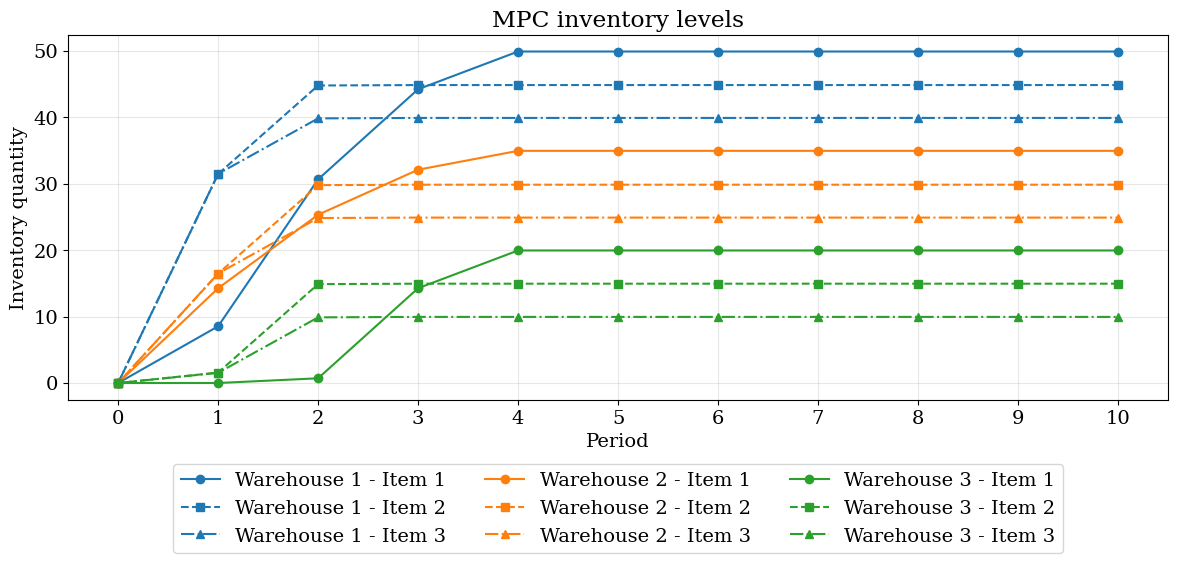

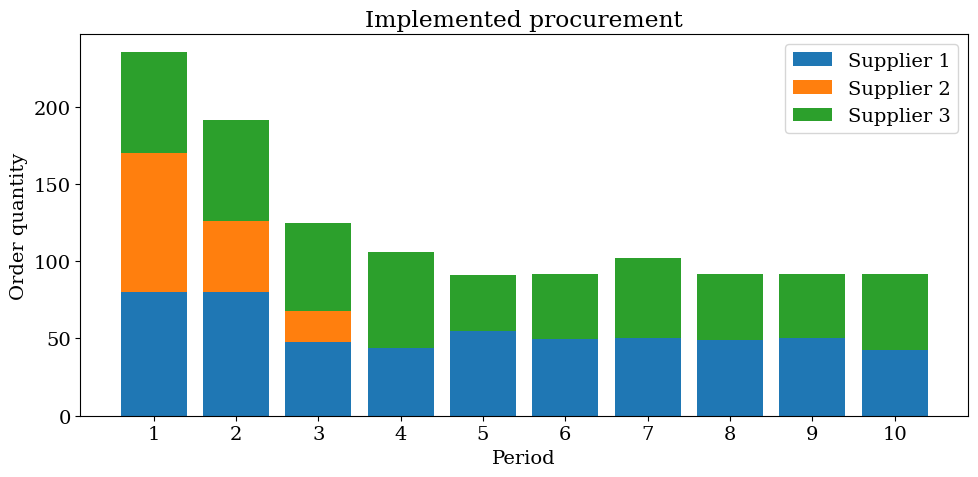

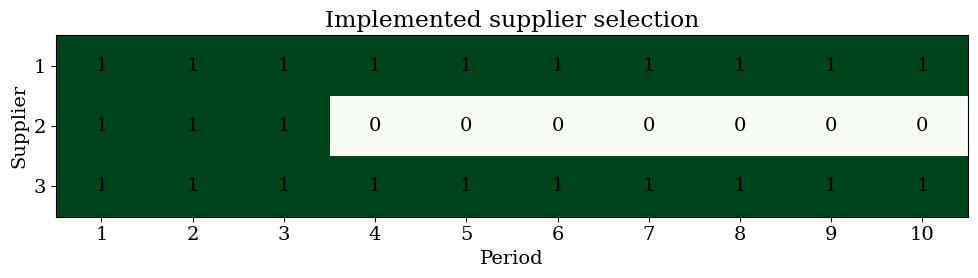

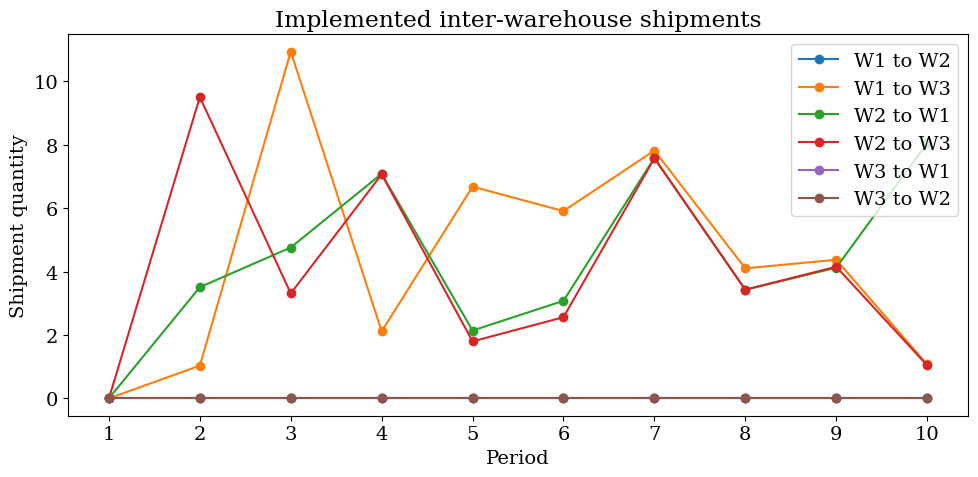

In [ ]:
import matplotlib.pyplot as plt
periods = np.arange(1,N+1)
warehouses, suppliers, items = np.arange(1,len(W)+1), np.arange(1,len(S)+1), np.arange(1,len(I)+1)

fig, ax = plt.subplots(figsize=(12,6))
for w,i in product(W,I):
    ax.plot(np.arange(N+1), np.r_[prevI[w,i],history['Inv'][:,w,i]], color=f'C{w}', linestyle=['-','--','-.'][i], marker=['o','s','^'][i], label=f'Warehouse {w+1} - Item {i+1}')
ax.set(xlabel='Period',ylabel='Inventory quantity',title='MPC inventory levels',xticks=np.arange(N+1))
ax.legend(ncol=3,loc='upper center',bbox_to_anchor=(.5,-.15)); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig('MPC_Inventory.png',dpi=300); plt.show()

fig, ax = plt.subplots(figsize=(10,5))
bottom=np.zeros(N)
for s in S:
    values=history['X'][:,:,s,:].sum(axis=(1,2))
    ax.bar(periods,values,bottom=bottom,label=f'Supplier {s+1}'); bottom+=values
ax.set(xlabel='Period',ylabel='Order quantity',title='Implemented procurement',xticks=periods); ax.legend(); plt.tight_layout(); plt.savefig('MPC_X.png',dpi=300); plt.show()

fig,ax=plt.subplots(figsize=(10,3))
ax.imshow(history['Y'].T,aspect='auto',vmin=0,vmax=1,cmap='Greens')
for s,t in product(S,range(N)): ax.text(t,s,str(round(history['Y'][t,s])),ha='center',va='center')
ax.set(xticks=range(N),xticklabels=periods,yticks=list(S),yticklabels=suppliers,xlabel='Period',ylabel='Supplier',title='Implemented supplier selection'); plt.tight_layout(); plt.savefig('MPC_Y.png',dpi=300); plt.show()

fig,ax=plt.subplots(figsize=(10,5))
for v,w in product(W,W):
    if v!=w: ax.plot(periods,history['WS'][:,v,w,:].sum(axis=1),marker='o',label=f'W{v+1} to W{w+1}')
ax.set(xlabel='Period',ylabel='Shipment quantity',title='Implemented inter-warehouse shipments',xticks=periods); ax.legend(); plt.tight_layout(); plt.savefig('MPC_WS.png',dpi=300); plt.show()


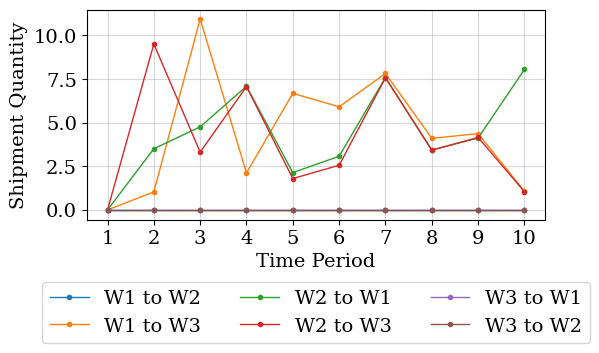

In [ ]:
fig,ax=plt.subplots(figsize=(6,4))
for v,w in product(W,W):
    if v!=w: ax.plot(periods,history['WS'][:,v,w,:].sum(axis=1),marker='.',linewidth=1,label=f'W{v+1} to W{w+1}')
ax.set(xlabel='Time Period',ylabel='Shipment Quantity',xticks=periods);
ax.legend(
    ncol=3,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.25)
)
ax.grid(alpha=0.5)
plt.tight_layout(); plt.savefig('MPC_WS.pdf');
plt.show()


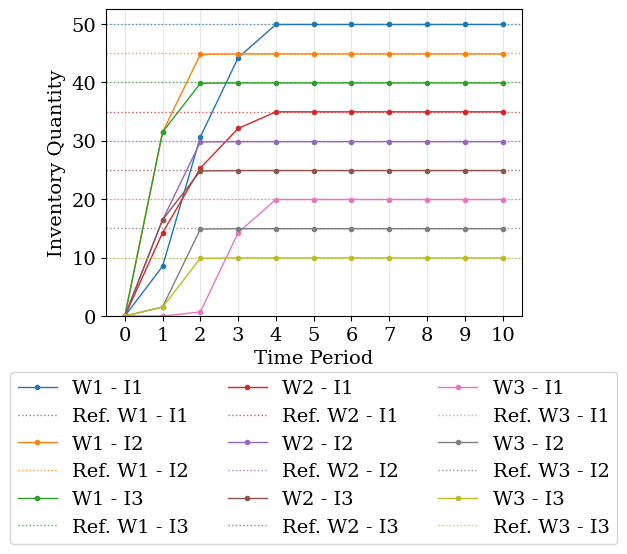

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))

colors = plt.cm.tab10.colors
linestyles = ['-', '-', '-']
markers = ['.', '.', '.']

for w, i in product(W, I):

    color = colors[w * len(I) + i]

    # Implemented inventory trajectory
    ax.plot(
        np.arange(N+1),
        np.r_[prevI[w,i], history['Inv'][:,w,i]],
        color=color,
        linestyle=linestyles[i],
        marker=markers[i],
        linewidth=1,
        label=f'W{w+1} - I{i+1}'
    )

    # Reference inventory level
    ax.axhline(
        y=Iref_full[0,w,i],
        color=color,
        linestyle=':',
        linewidth=1,
        alpha=0.8,
        label=f'Ref. W{w+1} - I{i+1}'
    )

ax.set(
    xlabel='Time Period',
    ylabel='Inventory Quantity',
    xticks=np.arange(N+1)
)

ax.set_ylim(bottom=0)

ax.legend(
    ncol=3,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.15)
)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('MPC_Inventory.pdf',
            bbox_inches='tight')
plt.show()

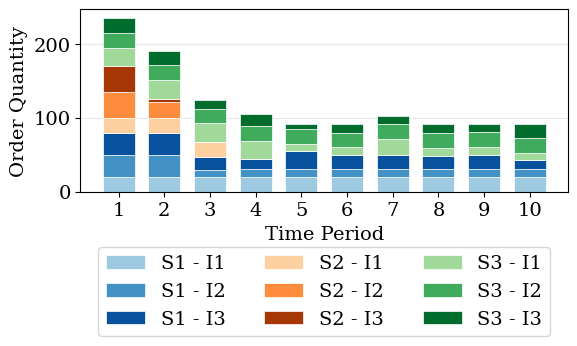

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))

bottom = np.zeros(N)

# Nine distinct colors
colors = [
    '#9ECAE1', '#4292C6', '#08519C',  # Supplier 1: Blue
    '#FDD0A2', '#FD8D3C', '#A63603',  # Supplier 2: Orange
    '#A1D99B', '#41AB5D', '#006D2C'   # Supplier 3: Green
]

for s in S:
    for i in I:

        # Aggregate order quantities across all warehouses
        values = history['X'][:, :, s, i].sum(axis=1)

        ax.bar(
            periods,
            values,
            bottom=bottom,
            color=colors[s * len(I) + i],
            edgecolor='white',
            linewidth=0.5,
            width=0.7,
            label=f'S{s+1} - I{i+1}'
        )

        bottom += values

ax.set(
    xlabel='Time Period',
    ylabel='Order Quantity',
    xticks=periods
)

ax.legend(
    ncol=3,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.25)
)

ax.set_ylim(bottom=0)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('MPC_X.pdf', bbox_inches='tight')
plt.show()

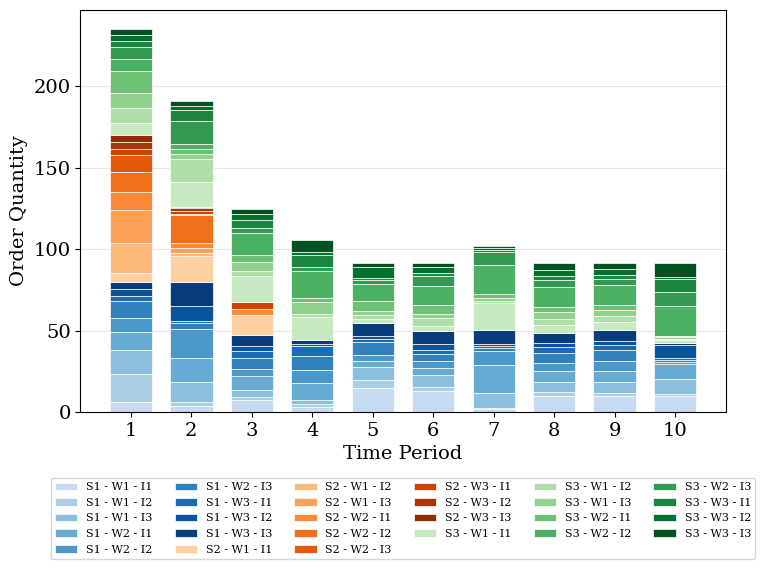

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))

bottom = np.zeros(N)

# Color palettes for each supplier
cmaps = [plt.cm.Blues, plt.cm.Oranges, plt.cm.Greens]

for s in S:
    for w in W:
        for i in I:

            # Order quantity for each warehouse, supplier, and item
            values = history['X'][:, w, s, i]

            # Different color shades
            color = cmaps[s](
                0.25 + 0.70 * (w * len(I) + i)
                / (len(W) * len(I) - 1)
            )

            ax.bar(
                periods,
                values,
                bottom=bottom,
                color=color,
                edgecolor='white',
                linewidth=0.5,
                width=0.7,
                label=f'S{s+1} - W{w+1} - I{i+1}'
            )

            bottom += values

ax.set(
    xlabel='Time Period',
    ylabel='Order Quantity',
    xticks=periods
)

ax.legend(
    ncol=6,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.15),
    fontsize=8
)

ax.set_ylim(bottom=0)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('MPC_X.pdf', bbox_inches='tight')
plt.show()

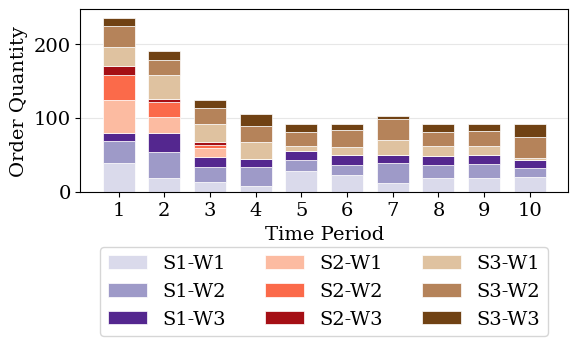

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))

bottom = np.zeros(N)

colors = [
    '#DADAEB', '#9E9AC8', '#54278F',  # Supplier 1: Purple
    '#FCBBA1', '#FB6A4A', '#A50F15',  # Supplier 2: Red
    '#DFC2A0', '#B5835A', '#704214'   # Supplier 3: Brown
]

for s in S:
    for w in W:

        values = history['X'][:, w, s, :].sum(axis=1)

        ax.bar(
            periods,
            values,
            bottom=bottom,
            color=colors[s * len(W) + w],
            edgecolor='white',
            linewidth=0.5,
            width=0.7,
            label=f'S{s+1}-W{w+1}'
        )

        bottom += values

ax.set(
    xlabel='Time Period',
    ylabel='Order Quantity',
    xticks=periods
)

ax.legend(
    ncol=3,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.25)
)

ax.set_ylim(bottom=0)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('MPC_X_Supplier_Warehouse.pdf', bbox_inches='tight')
plt.show()

In [ ]:
with pd.ExcelWriter('MPC_results.xlsx',engine='openpyxl') as writer:
    for name,df in results.items(): df.to_excel(writer,sheet_name=name,index=False)
    costs.to_excel(writer,sheet_name='Costs',index=False)
    solver_log.to_excel(writer,sheet_name='Solver log',index=False)
    pd.DataFrame([ (t+1,w+1,i+1,DE_full[t,w,i],Iref_full[t,w,i]) for t,w,i in product(range(N+H-1),W,I)],columns=['Time','Warehouse','Item','Demand','Reference']).to_excel(writer,sheet_name='Forecasts',index=False)
files.download('MPC_results.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>